# Stock 4: a perfect clue that's missing, and noise that hides in x5

For stock 4 the hard part is not the model. It's spotting **two traps** before you trust any score: one that makes bad models look brilliant, and one that makes good models look bad.

### The plan

| Part | What we do |
|---|---|
| 1 | Load and check the data |
| 2 | Look at the data and find the traps |
| 3 | Compare many models fairly |
| 4 | Mix the best models (blending) |
| 5 | Predict stock 4 |
| 6 | Measure how sure we are |
| 7 | Make a quote and a trading plan |

### Words used in this notebook

| Word | Meaning |
|---|---|
| **Clue** (= feature) | One column of the data, `x1` to `x7`. A measurement that might help predict the price. |
| **Noise** | The part of the price that no clue can explain. |
| **Quiet zone** | Rows where `x5` is close to 0 (\|x5\| < 0.05). There the noise is tiny, and the test row lives there. |
| **CV RMSE** | How many pounds the model is wrong by, on average, on rows it hasn't seen. Smaller is better. |
| **Quiet-zone CV RMSE** | The same, but only counting rows in the quiet zone. **This is the score that matters for our test row.** |
| **Weighted regression** | A model that trusts some rows more than others. Here: it trusts quiet rows more. |
| **OOF prediction** | "Out-of-fold": a prediction for a row made by a model that never saw that row. |

Run the cells from top to bottom (or **Restart**, then **Run All**). Part 3 takes about 15 minutes.

---
# Part 1: Load and check the data

### Step 1.1: Load the tools

In [1]:
import warnings
warnings.filterwarnings("ignore")          # hide harmless library warnings so the output stays readable

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats
from scipy.optimize import nnls

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer, PolynomialFeatures
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, KFold, cross_val_score, cross_val_predict
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, HuberRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

pd.set_option("display.max_colwidth", None)    # show long text in tables in full, without "..."
print("All tools loaded.")

All tools loaded.


### Step 1.2: Open the data files

In [2]:
DATA_DIR = Path("../datasets")     # the data folder is one level up from this notebook
if not DATA_DIR.exists():          # in case the notebook was started from the main folder instead
    DATA_DIR = Path("datasets")

train = pd.read_csv(DATA_DIR / "stock_4_train.csv")   # the examples we learn from
test = pd.read_csv(DATA_DIR / "stock_4_test.csv")     # the one row we must price


clue_columns = [c for c in train.columns if c.startswith("x")]   # x1 ... x7

print("Training data:", train.shape[0], "rows")
print("Test data:    ", test.shape[0], "row")
print("Clues:        ", len(clue_columns))
train.head()

Training data: 30000 rows
Test data:     1 row
Clues:         7


,uid,x1,x2,x3,x4,x5,x6,x7,price
0,9b96e44d46,-0.2271,0.2489,0.2810,0.0684,-0.7639,-0.7999,53.9838,54.53
1,eecc6227cf,-0.5377,0.2777,0.8802,0.2136,0.0109,-0.8304,47.1610,47.28
2,867996c020,-0.7028,0.3785,0.1178,-0.5801,0.4563,0.1693,53.8849,53.95
3,c75b111395,-0.9095,0.6272,-0.3941,-0.0973,-0.2209,-0.5758,52.8762,53.58
4,22a5cb1ec6,-0.4784,0.9700,-0.0402,0.1247,0.3094,0.3135,62.8565,63.24


30,000 rows and only 7 clues, so this time there is plenty of data. Clues `x1`–`x6` sit between −1 and +1; `x7` is on a completely different scale (around 60). Keep an eye on `x7`.

### Step 1.3: Quick health check

We look for empty cells and repeated rows, in the training data **and** in the test row.

In [3]:
print("Empty cells in train:", train.isna().sum().sum())
print("Repeated rows in train:", train[clue_columns].duplicated().sum())
print("\nThe test row:")
test

Empty cells in train: 0
Repeated rows in train: 0

The test row:


,id,uid,x1,x2,x3,x4,x5,x6,x7
0,stock_4,cd5961ff64,0.4061,-0.6349,0.1829,-0.7669,0.0354,0.5158,NaN


In [4]:
print("Empty cells in the test row, per clue:")
print(test[clue_columns].isna().sum().to_string())
print()
train["price"].describe().round(2)

Empty cells in the test row, per clue:
x1    0
x2    0
x3    0
x4    0
x5    0
x6    0
x7    1



count    30000.00
mean        63.48
std         12.02
min          6.18
25%         55.11
50%         63.49
75%         71.69
max        120.19
Name: price, dtype: float64

**The training data are perfectly clean, but the test row has an empty cell: `x7` is missing.** Nothing else is missing anywhere. That's not an accident, and Part 2 shows why it matters so much.

Prices average about **£63**, and most are within about £12 of that.

> **✅ Checkpoint.** 30,000 clean rows, 7 clues, and a test row with `x7` missing.

---
# Part 2: Look at the data

### Step 2.1: Is the test row "normal"?

Same two questions as in stock 2: is any clue outside the training range, and how far is each clue from the training average (in std steps)? We can only check `x1`–`x6`, since `x7` is empty.

In [5]:
six_clues = ["x1", "x2", "x3", "x4", "x5", "x6"]
test_row = test[six_clues].iloc[0]

check = pd.DataFrame({
    "test row": test_row,
    "smallest in training": train[six_clues].min(),
    "largest in training": train[six_clues].max(),
    "std steps from average": ((test_row - train[six_clues].mean()) / train[six_clues].std()).round(2),
})
check

,test row,smallest in training,largest in training,std steps from average
x1,0.4061,-0.9999,1.0000,0.70
x2,-0.6349,-0.9998,1.0000,-1.10
x3,0.1829,-0.9999,1.0000,0.32
x4,-0.7669,-0.9999,0.9999,-1.33
x5,0.0354,-1.0000,1.0000,0.07
x6,0.5158,-1.0000,0.9997,0.89


Every value is well inside the training range and within about 1.3 std steps of the average. Unlike stock 2, **the test row is not extreme**. Remember the value of `x5`, though: **0.035**, almost exactly 0. It turns out to be the most important number in this notebook.

### Step 2.2: Which clues are related to the price?

In [6]:
train[clue_columns].corrwith(train["price"]).round(3).to_frame("correlation with price")

,correlation with price
x1,0.712
x2,-0.001
x3,-0.286
x4,0.012
x5,0.002
x6,-0.008
x7,0.999


* `x7` has a correlation of **0.999** with price. That's almost perfect: `x7` is basically the price itself, copied with a little noise.
* `x1` (+0.71) and `x3` (−0.29) are clearly related to price.
* `x2`, `x4`, `x5`, `x6` look unrelated (about 0). **Correlation only measures straight-line relationships**, so we'll look at the pictures before believing that.

### Step 2.3: The first trap: the perfect clue is missing

How close is `x7` to the price, and what happens if a model relies on it?

In [7]:
gap = train["price"] - train["x7"]
print(f"price − x7: average £{gap.mean():.2f}, typical size (std) £{gap.std():.2f}")

cv = KFold(n_splits=5, shuffle=True, random_state=0)
rmse_with_x7 = -cross_val_score(LinearRegression(), train[clue_columns], train["price"], cv=cv,
                                scoring="neg_root_mean_squared_error").mean()
print(f"CV RMSE of a linear regression that uses x7: £{rmse_with_x7:.2f}   (looks amazing)")

# What would such models say about our test row, where x7 is empty?
X7, y7, T7 = train[clue_columns], train["price"], test[clue_columns]
trap = pd.DataFrame([
    {"approach (uses x7)": "Linear regression, empty x7 filled with the average",
     "test prediction (£)": LinearRegression().fit(X7, y7).predict(T7.fillna(X7.mean()))[0]},
    {"approach (uses x7)": "Linear regression, empty x7 filled with 0",
     "test prediction (£)": LinearRegression().fit(X7, y7).predict(T7.fillna(0))[0]},
    {"approach (uses x7)": "sklearn gradient boosting, empty cell left in",
     "test prediction (£)": HistGradientBoostingRegressor(random_state=0).fit(X7, y7).predict(T7)[0]},
    {"approach (uses x7)": "XGBoost, empty cell left in",
     "test prediction (£)": XGBRegressor(random_state=0).fit(X7, y7).predict(T7)[0]},
    {"approach (uses x7)": "LightGBM, empty cell left in",
     "test prediction (£)": LGBMRegressor(random_state=0, verbose=-1).fit(X7, y7).predict(T7)[0]},
])
trap["test prediction (£)"] = trap["test prediction (£)"].round(2)
trap

price − x7: average £-0.00, typical size (std) £0.40
CV RMSE of a linear regression that uses x7: £0.40   (looks amazing)


,approach (uses x7),test prediction (£)
0,"Linear regression, empty x7 filled with the average",63.49
1,"Linear regression, empty x7 filled with 0",0.22
2,"sklearn gradient boosting, empty cell left in",63.81
3,"XGBoost, empty cell left in",102.94
4,"LightGBM, empty cell left in",29.15


**How to read this**

* `x7` is the price plus about **£0.40** of noise. A model that uses it gets a CV RMSE of about **£0.40**, the best score anyone will see on this stock.
* But the test row **has no `x7`**. Every model that leans on `x7` has to invent a value, and the answers are all over the place: from about **£0** to about **£103**, depending on how the empty cell is handled. None of them is a real prediction.
* Could we "fill in" `x7` by predicting it from `x1`–`x6`? That's exactly the same job as predicting the price from `x1`–`x6`, so it adds nothing.

**Decision: we drop `x7` completely.** From here on, every model uses only `x1`–`x6`.

**Why this matters for the game.** A team that falls into this trap sees a CV RMSE of £0.40 and feels very confident, so it quotes **tightly**, around the wrong price (often about £63.5, the average). Tight quotes win the market-maker seat. We come back to this in Part 7: it's our biggest opportunity on stock 4.

### Step 2.4: What shape does each clue's effect have?

Correlation missed some things, so let's look. For each clue we cut its values into 20 slices and plot the **average price** in each slice. The dashed line is the test row's value.

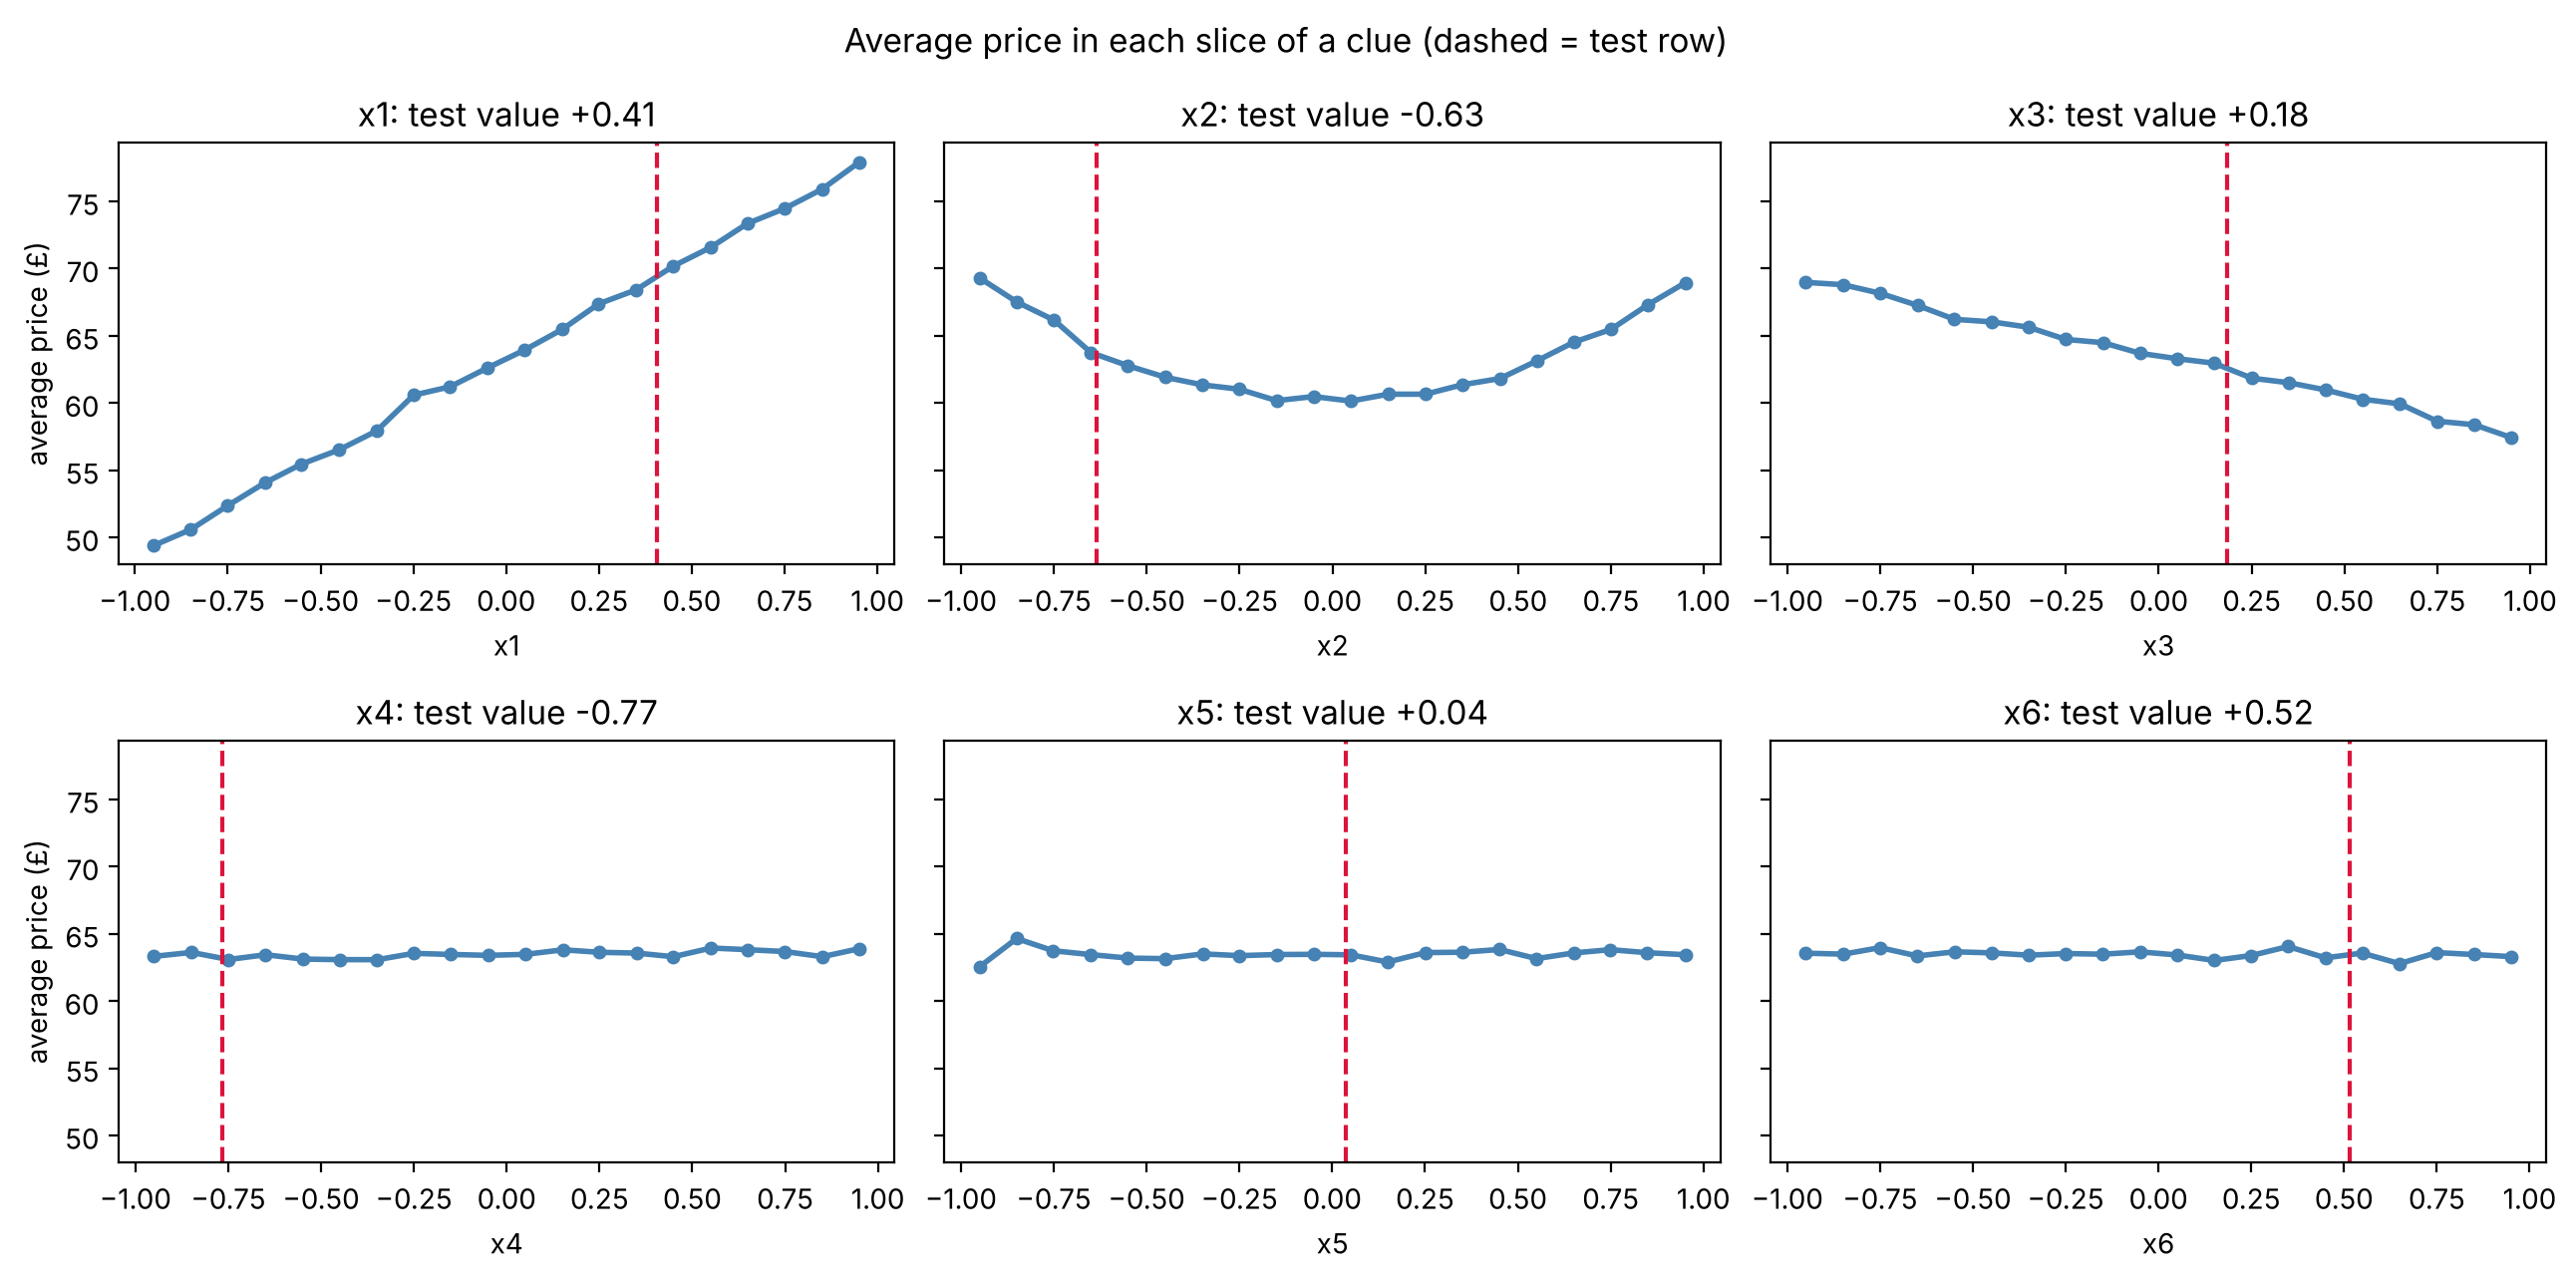

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5), sharey=True)
for ax, clue in zip(axes.flat, six_clues):
    slices = pd.cut(train[clue], 20)
    avg = train.groupby(slices, observed=True)["price"].mean()
    centres = train.groupby(slices, observed=True)[clue].mean()
    ax.plot(centres, avg, marker="o", markersize=4, linewidth=2, color="steelblue")
    ax.axvline(test_row[clue], color="crimson", linestyle="--", linewidth=1.5)
    ax.set_title(f"{clue}: test value {test_row[clue]:+.2f}")
    ax.set_xlabel(clue)
axes[0, 0].set_ylabel("average price (£)")
axes[1, 0].set_ylabel("average price (£)")
fig.suptitle("Average price in each slice of a clue (dashed = test row)")
plt.tight_layout()
plt.show()

**What do you see?**

* `x1`: a straight line **up**.
* `x2`: a **U-shape** (a "smile"): the price is higher when `x2` is far from 0 on **either** side. That's why its correlation was 0: the left half goes down and the right half goes up, and they cancel out. A straight-line model can't see this at all. The fix is easy: give the model `x2²` (x2 squared) instead of `x2`.
* `x3`: a straight line **down**.
* `x4`, `x5`, `x6`: flat. They don't change the average price.

So a natural guess is: **price ≈ start + a × x1 + b × x2² + c × x3**. We'll call this the **3-clue line**.

### Step 2.5: The second trap: the noise hides in x5

`x5` doesn't change the average price. But does it change **how noisy** the price is?

We fit the 3-clue line, take its errors (real − predicted), and look at how big the errors are for different values of `x5`.

In [9]:
def three_clues(d):
    # the 3 ingredients found in Step 2.4: x1, x2 squared, x3
    return np.column_stack([d["x1"], d["x2"] ** 2, d["x3"]])

line_3 = LinearRegression().fit(three_clues(train), train["price"])
errors = train["price"] - line_3.predict(three_clues(train))

# typical error size (std) in 20 slices of |x5|
slices = pd.cut(train["x5"].abs(), np.linspace(0, 1, 21))
noise_table = pd.DataFrame({
    "average |x5|": train["x5"].abs().groupby(slices, observed=True).mean(),
    "typical error (std, £)": errors.groupby(slices, observed=True).std(),
    "rows": errors.groupby(slices, observed=True).size(),
})

# a simple formula for the noise: std ≈ a + b × x5²
noise_fit = LinearRegression().fit(noise_table[["average |x5|"]] ** 2, noise_table["typical error (std, £)"])
a, b = noise_fit.intercept_, noise_fit.coef_[0]

def noise_sd(x5):
    # typical size of the unpredictable part of the price, for a given x5
    return a + b * np.asarray(x5) ** 2

print(f"Noise formula: typical error ≈ £{a:.2f} + £{b:.2f} × x5²")
print(f"Overall typical error (all rows): £{errors.std():.2f}")
print(f"Typical error at the test row's x5 = {test_row['x5']:.3f}:  £{float(noise_sd(test_row['x5'])):.2f}")
noise_table.round(3)

Noise formula: typical error ≈ £0.53 + £14.86 × x5²
Overall typical error (all rows): £7.07
Typical error at the test row's x5 = 0.035:  £0.54


,average |x5|,"typical error (std, £)",rows
x5,,,
"(0.0, 0.05]",0.025,0.513,1525
"(0.05, 0.1]",0.075,0.606,1434
"(0.1, 0.15]",0.125,0.753,1560
"(0.15, 0.2]",0.175,0.975,1476
"(0.2, 0.25]",0.225,1.267,1466
"(0.25, 0.3]",0.276,1.589,1496
"(0.3, 0.35]",0.325,2.104,1444
"(0.35, 0.4]",0.374,2.586,1469
"(0.4, 0.45]",0.425,3.126,1449


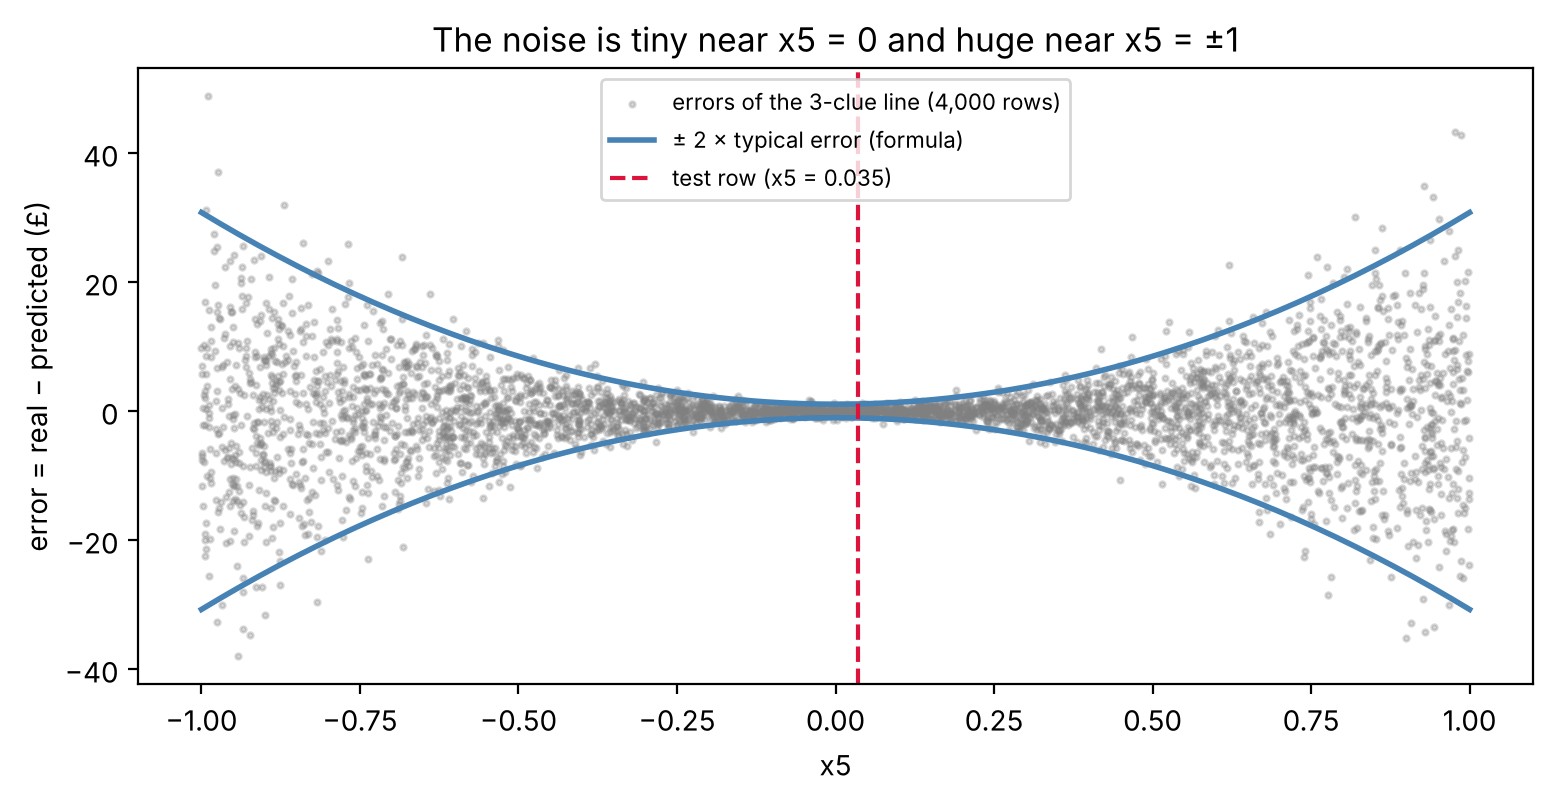

In [10]:
sample = train.sample(4000, random_state=0)
xs = np.linspace(-1, 1, 200)

plt.figure(figsize=(9, 4))
plt.scatter(sample["x5"], errors[sample.index], s=4, alpha=0.3, color="grey", label="errors of the 3-clue line (4,000 rows)")
plt.plot(xs, 2 * noise_sd(xs), color="steelblue", linewidth=2, label="± 2 × typical error (formula)")
plt.plot(xs, -2 * noise_sd(xs), color="steelblue", linewidth=2)
plt.axvline(test_row["x5"], color="crimson", linestyle="--", linewidth=1.5, label=f"test row (x5 = {test_row['x5']:.3f})")
plt.xlabel("x5"); plt.ylabel("error = real − predicted (£)")
plt.title("The noise is tiny near x5 = 0 and huge near x5 = ±1")
plt.legend(loc="upper center", fontsize=8)
plt.show()

**How to read this**

* Near **x5 = 0** the errors are tiny, about **£0.5**. Near **x5 = ±1** they are about **£15**, thirty times bigger.
* Averaged over all rows the typical error is about **£7**. That's the number most teams will use to size their quote.
* Our test row has **x5 = 0.035**, right in the quietest part. Its noise should be about **£0.5**, not £7.

This is the **opposite of stock 2**. There the CV RMSE was too optimistic for an extreme row. Here the overall CV RMSE is about **13 times too pessimistic** for our row, because it's an average over mostly noisy rows.

From now on we measure every model twice: on all rows, and on the **quiet zone** (|x5| < 0.05, about 1,500 rows, 5% of the data), which is where the test row lives.

> **✅ Checkpoint.** Stock 4 has two traps: (1) `x7` is a near-perfect clue that's **missing from the test row**; (2) the noise depends on `x5`, and the test row sits where the noise is tiny. Also, `x2` matters through a U-shape that straight lines can't see.

---
# Part 3: Compare models fairly

### Step 3.1: The fair-test setup

* **5-fold cross-validation**, once. With 30,000 rows each fold has 6,000 rows to test on, so the scores are already very stable and repeating the cuts (like we did for stock 2's 140 rows) isn't needed.
* **Random cuts are fine here.** If the rows were in time order, random cuts would let the model peek at the future. We check below: neighbouring rows are unrelated, so the order carries no information.
* **Two scores per model:** CV RMSE on all rows, and quiet-zone CV RMSE. **We choose each model's settings by the quiet-zone score**, because that's the situation of our test row.
* Every model sees **only `x1`–`x6`**.

In [11]:
X = train[six_clues]             # the clues (x7 dropped on purpose)
y = train["price"]               # the answers
X_test = test[six_clues]         # the test row's clues

QUIET = 0.05                     # quiet zone: |x5| < 0.05
print("Rows in the quiet zone:", (X["x5"].abs() < QUIET).sum())
print(f"Neighbouring rows, correlation of their errors: {pd.Series(errors.values).autocorr(1):.3f}   (0 = row order carries no information)")

cv = KFold(n_splits=5, shuffle=True, random_state=0)   # 5 fair tests

def quiet_zone_rmse(model, X_part, y_part):
    # RMSE counting only the rows where |x5| < 0.05 (sklearn maximises, so we return it negative)
    quiet = (X_part["x5"].abs() < QUIET).values
    predicted = np.ravel(model.predict(X_part[quiet]))
    return -np.sqrt(np.mean((y_part.values[quiet] - predicted) ** 2))

scoring = {"all": "neg_root_mean_squared_error", "quiet": quiet_zone_rmse}

Rows in the quiet zone: 1521
Neighbouring rows, correlation of their errors: 0.009   (0 = row order carries no information)


### Step 3.2: The models and their settings

All models go inside a **Pipeline** (first `StandardScaler`, then the model), exactly like stock 2.

**Group A, checked with GridSearchCV** (every combination):

| Model | Setting | What it controls |
|---|---|---|
| Linear regression | (none) | Plain straight line on `x1`–`x6`. |
| Ridge / Lasso / ElasticNet | `alpha` (`l1_ratio`) | How hard the weights are shrunk. |
| Huber | `epsilon` | A straight line that pays less attention to very large errors. |
| Random forest | `min_samples_leaf` | Smallest group of rows at the end of a branch. |
| SVR | `C` | Support vector regression: a flexible curve; `C` = how hard it tries to fit every row. |
| MLP | `hidden_layer_sizes`, `alpha` | A small neural network: its size, and how much it's held back. |

**Group B, checked with RandomizedSearchCV** (12 random combinations each): XGBoost, LightGBM, CatBoost.

In [12]:
grid_models = {
    "Linear regression": (LinearRegression(), {}),
    "Ridge": (Ridge(), {"model__alpha": np.logspace(-2, 3, 6)}),
    "Lasso": (Lasso(max_iter=20000), {"model__alpha": np.logspace(-3, 0, 6)}),
    "ElasticNet": (ElasticNet(max_iter=20000), {"model__alpha": np.logspace(-3, 0, 4),
                                                "model__l1_ratio": [0.2, 0.5, 0.8]}),
    "Huber": (HuberRegressor(max_iter=1000), {"model__epsilon": [1.35, 2.0, 3.0]}),
    "Random forest": (RandomForestRegressor(n_estimators=200, random_state=0, n_jobs=1),
                      {"model__min_samples_leaf": [5, 20, 50]}),
    "SVR": (SVR(epsilon=0.5, cache_size=1000), {"model__C": [3, 30]}),
    "MLP": (MLPRegressor(max_iter=500, early_stopping=True, random_state=0),
            {"model__hidden_layer_sizes": [(64, 32), (128, 64)], "model__alpha": [1e-4, 1e-2]}),
}
print("Group A models:", list(grid_models.keys()))

Group A models: ['Linear regression', 'Ridge', 'Lasso', 'ElasticNet', 'Huber', 'Random forest', 'SVR', 'MLP']


In [13]:
random_models = {
    "XGBoost": (XGBRegressor(random_state=0, n_jobs=1),
                {"model__n_estimators": [300, 600, 1000],
                 "model__learning_rate": [0.02, 0.05, 0.1],
                 "model__max_depth": [3, 4, 6],
                 "model__min_child_weight": [1, 5, 20],
                 "model__subsample": [0.7, 0.85, 1.0],
                 "model__colsample_bytree": [0.7, 1.0],
                 "model__reg_lambda": [1, 5, 10]}),
    "LightGBM": (LGBMRegressor(random_state=0, n_jobs=1, subsample_freq=1, verbose=-1),
                 {"model__n_estimators": [300, 600, 1000],
                  "model__learning_rate": [0.02, 0.05, 0.1],
                  "model__num_leaves": [7, 15, 31],
                  "model__min_child_samples": [20, 50, 100],
                  "model__subsample": [0.7, 0.85, 1.0],
                  "model__colsample_bytree": [0.7, 1.0],
                  "model__reg_lambda": [0, 5, 10]}),
    "CatBoost": (CatBoostRegressor(random_seed=0, verbose=0, thread_count=1, allow_writing_files=False),
                 {"model__iterations": [500, 1000],
                  "model__learning_rate": [0.03, 0.06, 0.1],
                  "model__depth": [4, 6, 8],
                  "model__l2_leaf_reg": [1, 3, 10]}),
}
N_ITER = 12
print("Group B models:", list(random_models.keys()))

Group B models: ['XGBoost', 'LightGBM', 'CatBoost']


### Step 3.3: Run the contest

This takes about 10–15 minutes. For each model the search tries the settings, keeps the one with the best **quiet-zone** score, retrains it on all 30,000 rows, and prices the test row.

In [14]:
results = []
searches = {}

def record(name, search, fit_params=None):
    # save one finished search and its results
    searches[name] = (search, fit_params or {})
    i = search.best_index_
    results.append({
        "model": name,
        "CV RMSE, all rows (£)": round(-search.cv_results_["mean_test_all"][i], 2),
        "CV RMSE, quiet zone (£)": round(-search.cv_results_["mean_test_quiet"][i], 3),
        "test prediction (£)": round(float(np.ravel(search.predict(X_test))[0]), 2),
        "best settings": search.best_params_,
    })
    print(f"{name} done")

for name, (model, settings) in grid_models.items():
    pipe = Pipeline([("scaler", StandardScaler()), ("model", model)])
    search = GridSearchCV(pipe, settings, cv=cv, scoring=scoring, refit="quiet", n_jobs=-1)
    search.fit(X, y)
    record(name, search)

for name, (model, settings) in random_models.items():
    pipe = Pipeline([("scaler", StandardScaler()), ("model", model)])
    search = RandomizedSearchCV(pipe, settings, n_iter=N_ITER, cv=cv, random_state=0,
                                scoring=scoring, refit="quiet", n_jobs=-1)
    search.fit(X, y)
    record(name, search)

pd.DataFrame(results).sort_values("CV RMSE, quiet zone (£)").reset_index(drop=True)

Linear regression done


Ridge done
Lasso done


ElasticNet done


Huber done


Random forest done


SVR done


MLP done


XGBoost done


LightGBM done


CatBoost done


,model,"CV RMSE, all rows (£)","CV RMSE, quiet zone (£)",test prediction (£),best settings
0,SVR,7.14,0.592,68.79,{'model__C': 30}
1,CatBoost,7.13,0.675,68.85,"{'model__learning_rate': 0.03, 'model__l2_leaf_reg': 10, 'model__iterations': 500, 'model__depth': 8}"
2,MLP,7.10,0.767,68.65,"{'model__alpha': 0.01, 'model__hidden_layer_sizes': (64, 32)}"
3,XGBoost,7.10,0.788,69.63,"{'model__subsample': 0.85, 'model__reg_lambda': 10, 'model__n_estimators': 300, 'model__min_child_weight': 5, 'model__max_depth': 3, 'model__learning_rate': 0.05, 'model__colsample_bytree': 0.7}"
4,LightGBM,7.13,0.807,69.31,"{'model__subsample': 0.85, 'model__reg_lambda': 10, 'model__num_leaves': 7, 'model__n_estimators': 600, 'model__min_child_samples': 20, 'model__learning_rate': 0.05, 'model__colsample_bytree': 0.7}"
5,Random forest,7.25,0.976,69.58,{'model__min_samples_leaf': 5}
6,Lasso,7.70,3.071,68.37,{'model__alpha': 0.0630957344480193}
7,ElasticNet,7.70,3.072,68.28,"{'model__alpha': 0.01, 'model__l1_ratio': 0.8}"
8,Huber,7.70,3.072,68.28,{'model__epsilon': 2.0}
9,Linear regression,7.70,3.073,68.27,{}


**What this shows**

* On **all rows**, every model scores about the same (£7.1–£7.7). Judged by that number alone, they all look equally good, and equally bad.
* The **quiet zone** tells a very different story:
  * The straight-line models (linear regression, Ridge, Lasso, ElasticNet, Huber) are about **£3.07** off. They can't see the U-shape of `x2`, and no amount of tuning `alpha` fixes a wrong shape.
  * The flexible models learn the U-shape: SVR £0.59, CatBoost £0.68, MLP / XGBoost / LightGBM about £0.77–£0.81, random forest £0.98. But they spend most of their effort on the very noisy rows, which blurs the fine detail near `x5 = 0`.
* Their test-row prices range from **£68.27 to £69.63**: more than £1 apart, on a row where the noise is only about £0.5. We need to know which one to trust.

### Step 3.4: Use what we learned in Part 2

Part 2 taught us two things. Let's give them to the models:

1. **Use `x2²` instead of `x2`.** The 3-clue line from Step 2.4: `x1`, `x2²`, `x3`.
2. **Trust the quiet rows more.** A **weighted** regression gives each row a weight. A row whose noise is 10 times smaller gets 100 times more weight (weight = 1 / noise²), using the noise formula from Step 2.5. Think of it as listening more to the thermometers you know are accurate.

| Model | What's new |
|---|---|
| 3-clue line | Plain linear regression on `x1`, `x2²`, `x3` |
| Weighted 3-clue line | The same, with weights |
| Weighted cubic, all 6 clues | Every square, cube and pair of `x1`–`x6` (83 ingredients), weighted. A check: is anything else hiding? |
| Weighted LightGBM | The tree model from Group B, with weights |

(The noise formula was estimated on all the training rows. It's only two numbers that depend on `x5` alone, so the leak into the fair test is negligible.)

In [15]:
weights = pd.Series(1 / noise_sd(X["x5"]) ** 2, index=X.index)     # quiet rows count much more
weighted = {"model__sample_weight": weights.values}

extra_models = {
    "3-clue line": (Pipeline([("clues", FunctionTransformer(three_clues)), ("model", LinearRegression())]), {}, {}),
    "Weighted 3-clue line": (Pipeline([("clues", FunctionTransformer(three_clues)), ("model", LinearRegression())]), {}, weighted),
    "Weighted cubic, all 6 clues": (Pipeline([("clues", PolynomialFeatures(3)), ("model", LinearRegression())]), {}, weighted),
}
for name, (pipe, settings, fit_params) in extra_models.items():
    search = GridSearchCV(pipe, settings, cv=cv, scoring=scoring, refit="quiet", n_jobs=-1)
    search.fit(X, y, **fit_params)
    record(name, search, fit_params)

lgbm, lgbm_settings = random_models["LightGBM"]
search = RandomizedSearchCV(Pipeline([("scaler", StandardScaler()), ("model", lgbm)]), lgbm_settings,
                            n_iter=N_ITER, cv=cv, random_state=0, scoring=scoring, refit="quiet", n_jobs=-1)
search.fit(X, y, **weighted)
record("Weighted LightGBM", search, weighted)

results_table = pd.DataFrame(results).sort_values("CV RMSE, quiet zone (£)").reset_index(drop=True)
results_table

3-clue line done
Weighted 3-clue line done


Weighted cubic, all 6 clues done


Weighted LightGBM done


,model,"CV RMSE, all rows (£)","CV RMSE, quiet zone (£)",test prediction (£),best settings
0,Weighted 3-clue line,7.06,0.505,69.02,{}
1,"Weighted cubic, all 6 clues",7.07,0.513,68.97,{}
2,3-clue line,7.07,0.522,69.06,{}
3,SVR,7.14,0.592,68.79,{'model__C': 30}
4,Weighted LightGBM,7.07,0.601,69.51,"{'model__subsample': 0.85, 'model__reg_lambda': 10, 'model__num_leaves': 7, 'model__n_estimators': 600, 'model__min_child_samples': 20, 'model__learning_rate': 0.05, 'model__colsample_bytree': 0.7}"
5,CatBoost,7.13,0.675,68.85,"{'model__learning_rate': 0.03, 'model__l2_leaf_reg': 10, 'model__iterations': 500, 'model__depth': 8}"
6,MLP,7.10,0.767,68.65,"{'model__alpha': 0.01, 'model__hidden_layer_sizes': (64, 32)}"
7,XGBoost,7.10,0.788,69.63,"{'model__subsample': 0.85, 'model__reg_lambda': 10, 'model__n_estimators': 300, 'model__min_child_weight': 5, 'model__max_depth': 3, 'model__learning_rate': 0.05, 'model__colsample_bytree': 0.7}"
8,LightGBM,7.13,0.807,69.31,"{'model__subsample': 0.85, 'model__reg_lambda': 10, 'model__num_leaves': 7, 'model__n_estimators': 600, 'model__min_child_samples': 20, 'model__learning_rate': 0.05, 'model__colsample_bytree': 0.7}"
9,Random forest,7.25,0.976,69.58,{'model__min_samples_leaf': 5}


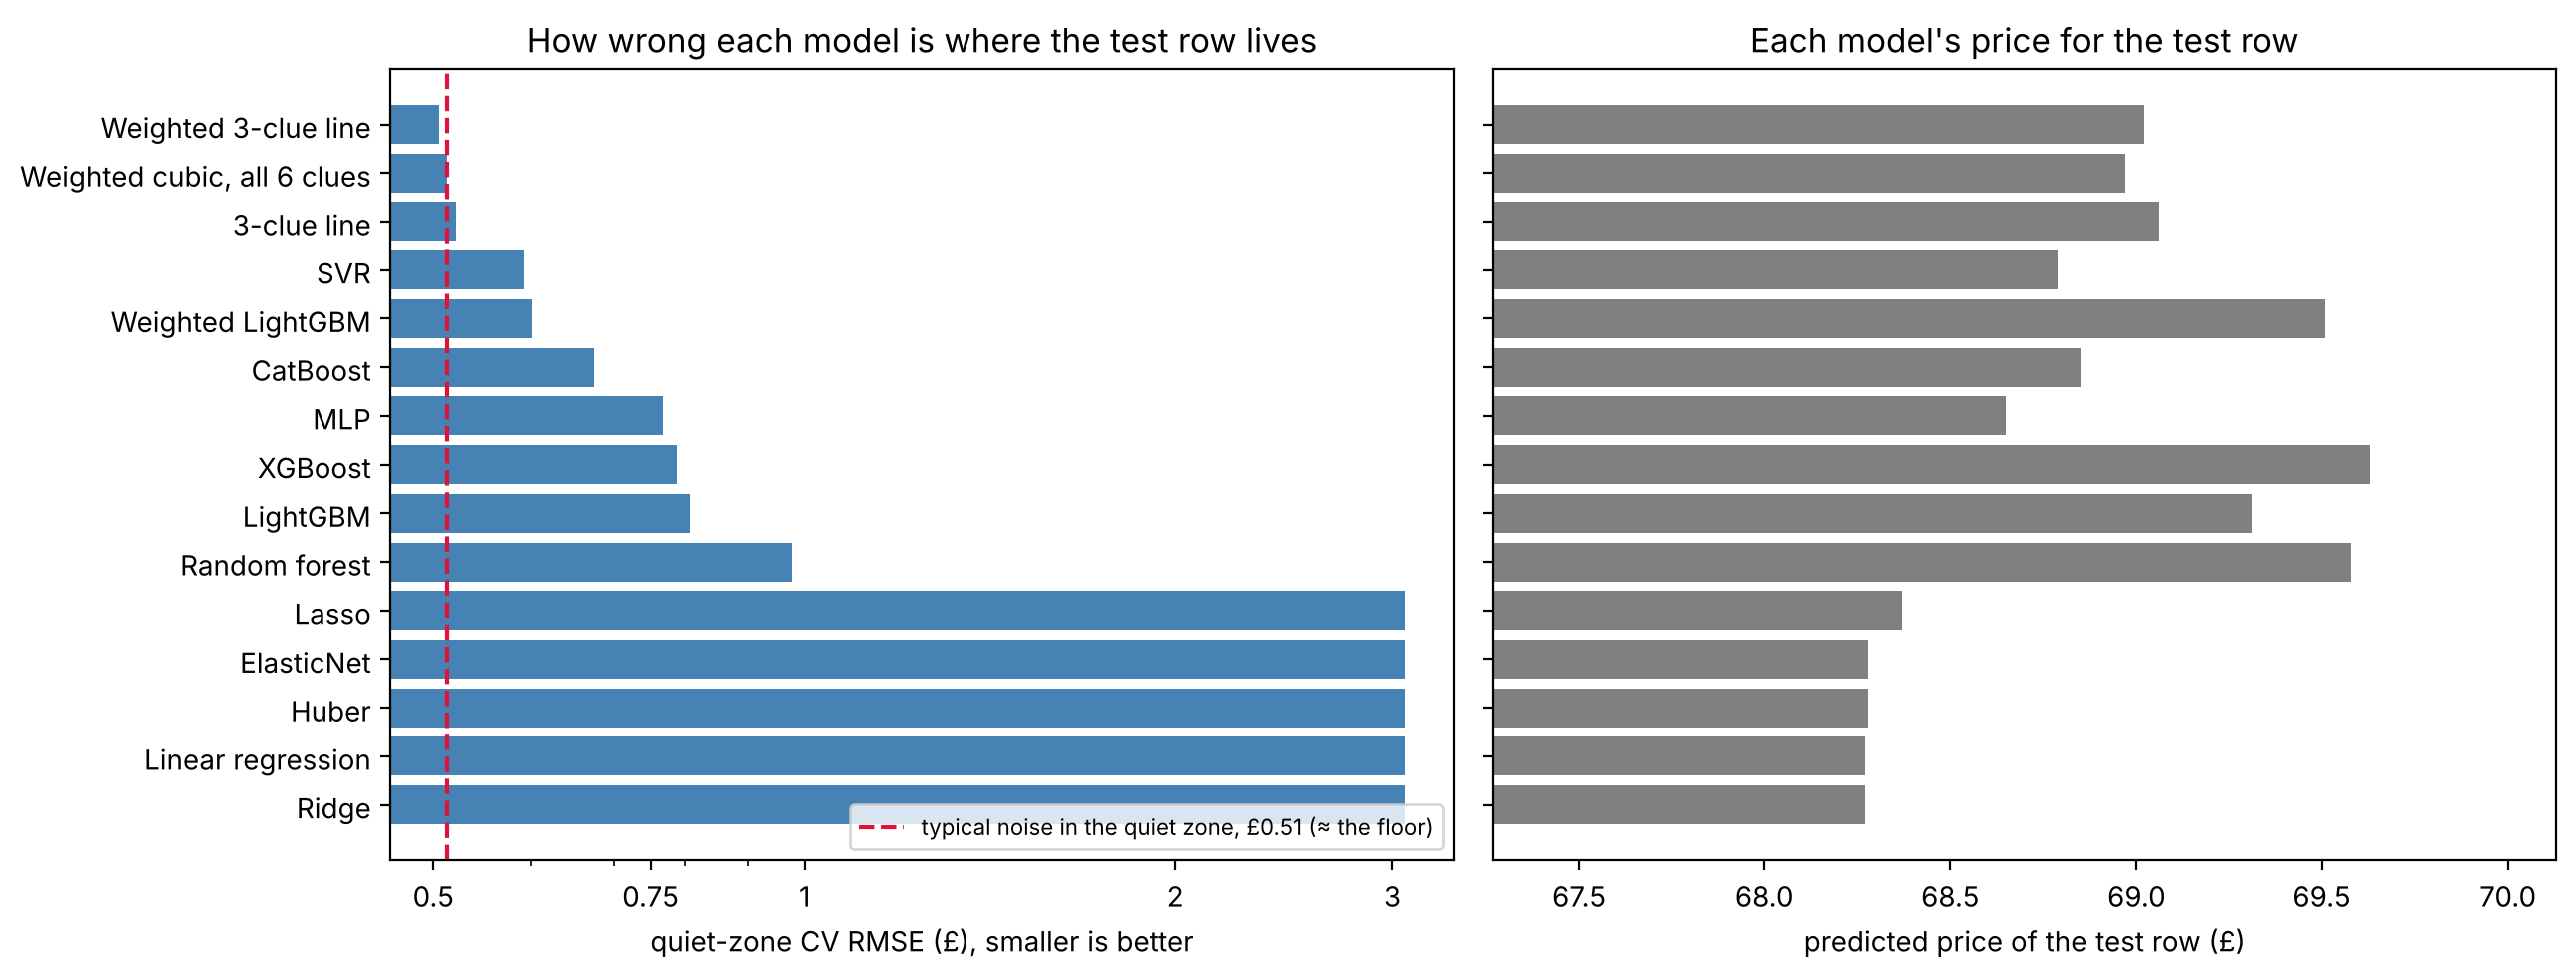

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

axes[0].barh(results_table["model"], results_table["CV RMSE, quiet zone (£)"], color="steelblue")
quiet_noise = noise_table["typical error (std, £)"].iloc[0]          # measured noise for |x5| < 0.05
axes[0].axvline(quiet_noise, color="crimson", linestyle="--", linewidth=1.5, label=f"typical noise in the quiet zone, £{quiet_noise:.2f} (≈ the floor)")
axes[0].set_xlabel("quiet-zone CV RMSE (£), smaller is better")
axes[0].set_title("How wrong each model is where the test row lives")
axes[0].set_xscale("log")
axes[0].set_xticks([0.5, 0.75, 1, 2, 3]); axes[0].set_xticklabels(["0.5", "0.75", "1", "2", "3"])
axes[0].xaxis.set_minor_formatter(plt.NullFormatter())
axes[0].legend(fontsize=8, loc="lower right")
axes[0].invert_yaxis()                                        # best model at the top

axes[1].barh(results_table["model"], results_table["test prediction (£)"], color="grey")
axes[1].set_xlabel("predicted price of the test row (£)")
axes[1].set_title("Each model's price for the test row")
axes[1].set_xlim(results_table["test prediction (£)"].min() - 1, results_table["test prediction (£)"].max() + 0.5)

plt.tight_layout()
plt.show()

**What this shows**

* The **weighted 3-clue line wins**: quiet-zone CV RMSE **£0.505**, about the size of the noise itself (red line). What's left is the unpredictable part, so no model can do much better.
* Even the plain 3-clue line (£0.52) beats every model from Groups A and B. **Giving the model the right shape (`x2²`) matters more than the choice of algorithm.**
* Weighting helps the tree model too (LightGBM: £0.81 → £0.60), but it still can't match the line.
* The **weighted cubic** has 83 ingredients (every square, cube and pair of `x1`–`x6`) and scores £0.513, slightly *worse* than 3 ingredients. So nothing else is hiding in `x4`, `x5` or `x6`.
* The three best models price the test row between **£68.97 and £69.06**.

> **✅ Checkpoint.** The winner is the **weighted 3-clue line**: simple, and right at the noise floor.

In [17]:
best_line = searches["Weighted 3-clue line"][0].best_estimator_.named_steps["model"]
w1, w2, w3 = best_line.coef_
print(f"Weighted 3-clue line:  price ≈ {best_line.intercept_:.2f} + {w1:.2f} × x1 + {w2:.2f} × x2² {w3:+.2f} × x3")

Weighted 3-clue line:  price ≈ 60.00 + 14.99 × x1 + 10.01 × x2² -6.00 × x3


Look at those numbers: **60.00 + 14.99 × x1 + 10.01 × x2² − 6.00 × x3**. Almost exactly round numbers. Stock 4 is synthetic, so this is very likely the organisers' recipe (60 + 15·x1 + 10·x2² − 6·x3) plus noise that grows with `x5`. When a model recovers round numbers like these, it's a strong sign it has found the true pattern and not a lucky fit.

---
# Part 4: Does mixing models help?

Sometimes an average of several different models beats the best single one, because their mistakes partly cancel. We test two ways of mixing the **5 best models** (by quiet-zone score):

1. **Simple average** of the top 3.
2. **Learned weights** ("stacking"): find the best non-negative weights for the 5 models. To keep it honest, we learn the weights on one half of the quiet rows and test them on the other half, then swap.

For this we need **OOF predictions**: for every row, a prediction from a model that never saw that row.

In [18]:
top5 = results_table["model"].head(5).tolist()
oof = {}
for name in top5:
    search, fit_params = searches[name]
    oof[name] = cross_val_predict(search.best_estimator_, X, y, cv=cv, params=fit_params, n_jobs=-1)
    print(f"{name}: OOF done")
oof = pd.DataFrame(oof)

quiet = (X["x5"].abs() < QUIET).values
yq, oq = y.values[quiet], oof[quiet].values
rmse = lambda p: np.sqrt(np.mean((yq - p) ** 2))

halves = np.random.default_rng(0).permutation(quiet.sum()) % 2       # two random halves of the quiet rows
stacked = np.zeros(quiet.sum())
for h in [0, 1]:
    learn, check = halves != h, halves == h
    w, _ = nnls(oq[learn], yq[learn])                # best non-negative weights on one half
    stacked[check] = oq[check] @ w                   # tested on the other half
w_all, _ = nnls(oq, yq)

blend_table = pd.DataFrame(
    [{"model": f"single: {n}", "quiet-zone OOF RMSE (£)": rmse(oq[:, i])} for i, n in enumerate(top5)]
    + [{"model": "simple average of top 3", "quiet-zone OOF RMSE (£)": rmse(oq[:, :3].mean(axis=1))},
       {"model": "learned weights (stacking, honest halves)", "quiet-zone OOF RMSE (£)": rmse(stacked)}]
).round(3)
print("\nLearned weights (all quiet rows):", dict(zip(top5, w_all.round(2))))
blend_table

Weighted 3-clue line: OOF done


Weighted cubic, all 6 clues: OOF done
3-clue line: OOF done


SVR: OOF done


Weighted LightGBM: OOF done

Learned weights (all quiet rows): {'Weighted 3-clue line': np.float64(1.0), 'Weighted cubic, all 6 clues': np.float64(0.0), '3-clue line': np.float64(0.0), 'SVR': np.float64(0.0), 'Weighted LightGBM': np.float64(0.0)}


,model,quiet-zone OOF RMSE (£)
0,single: Weighted 3-clue line,0.505
1,"single: Weighted cubic, all 6 clues",0.513
2,single: 3-clue line,0.522
3,single: SVR,0.592
4,single: Weighted LightGBM,0.602
5,simple average of top 3,0.509
6,"learned weights (stacking, honest halves)",0.506


**What this shows**

* Neither way of mixing beats the weighted 3-clue line on its own (£0.505): the simple average scores £0.509 and the stacked mix £0.506.
* The learned weights put **100% on the weighted 3-clue line** and 0% on the rest. Mixing helps when models make *different* mistakes. Here the line already captures everything except the noise, so the other models can only add their own errors.

> **✅ Checkpoint.** No mixing. The final model is the **weighted 3-clue line**.

---
# Part 5: Predict stock 4

### Step 5.1: Train the final model and predict

The **weighted 3-clue line**, trained on all 30,000 rows.

In [19]:
final_model = LinearRegression()
final_model.fit(three_clues(X), y, sample_weight=weights)        # learn from all 30,000 rows, quiet rows count more

prediction = final_model.predict(three_clues(X_test))[0]
print(f"Predicted price of stock 4: £{prediction:.2f}")

Predicted price of stock 4: £69.02


### Step 5.2: No magic, just arithmetic

In [20]:
names = ["x1", "x2²", "x3"]
values = three_clues(X_test)[0]
total = final_model.intercept_
print(f"start{'':24}{total:8.2f}")
for clue, weight, value in zip(names, final_model.coef_, values):
    total += weight * value
    print(f"+ {weight:6.2f} × {clue:3s} ({value:6.3f})   {weight * value:+8.2f}")
print(f"{'= prediction':29}{total:8.2f}")

start                           60.00
+  14.99 × x1  ( 0.406)      +6.09
+  10.01 × x2² ( 0.403)      +4.03
+  -6.00 × x3  ( 0.183)      -1.10
= prediction                    69.02


Three small, ordinary pieces: `x1` adds about £6, `x2²` adds about £4, `x3` takes off about £1. No extrapolation, no fragile cancellations (unlike stock 2).

> **✅ Checkpoint.** Our best guess is **£69.02**.

---
# Part 6: How sure are we?

### Step 6.1: The noise at the test row

The overall CV RMSE (about £7) is the wrong ruler: it's an average over mostly noisy rows. We want the error **for rows like ours**. So we take the final model's **OOF errors** for the training rows whose `x5` is close to the test row's (within ±0.025), and look at them.

Training rows with x5 within ±0.025 of the test row: 725
Their typical error (std): £0.528     average error: £+0.013
Noise formula at x5 = 0.035:  £0.544
Share of errors within ±1 std: 67% (bell shape: 68%)   within ±2 std: 95% (bell shape: 95%)
Bell-shape test p-value: 0.49   (above 0.05 = consistent with a bell shape)


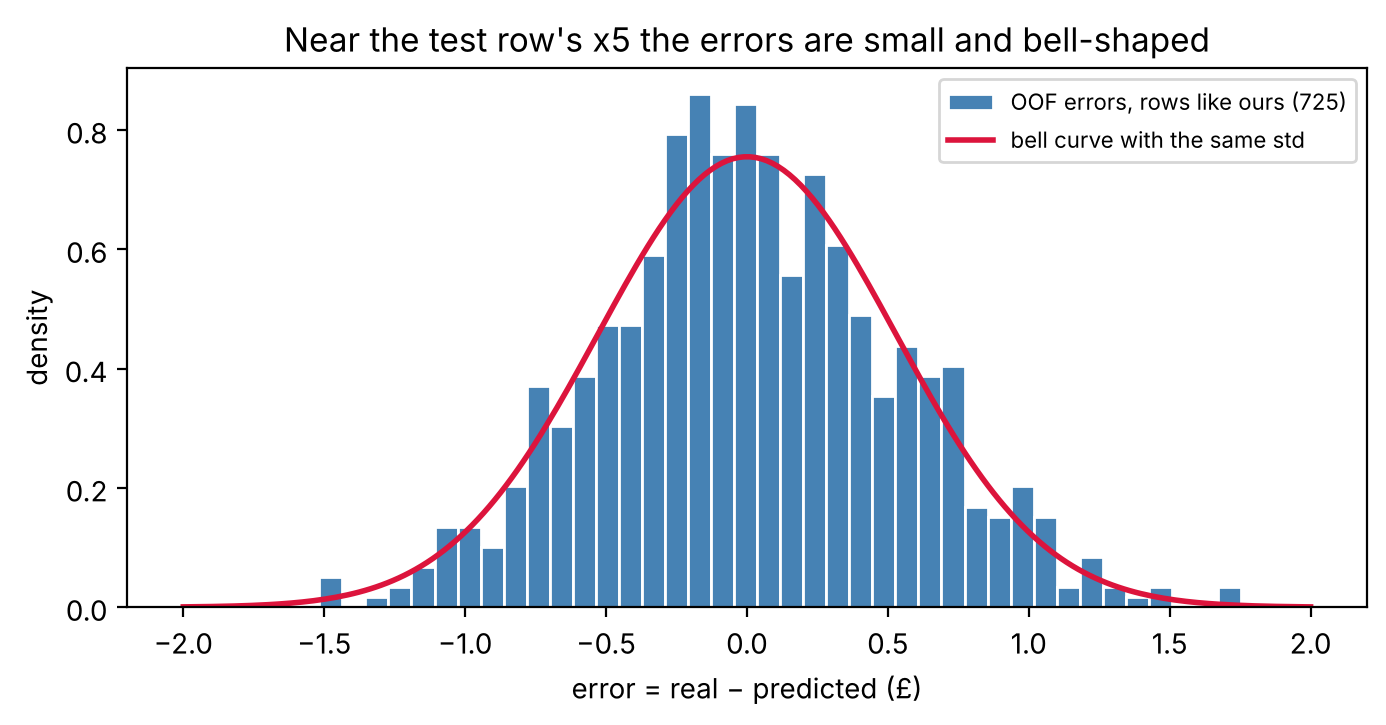

In [21]:
oof_final = cross_val_predict(
    Pipeline([("clues", FunctionTransformer(three_clues)), ("model", LinearRegression())]),
    X, y, cv=cv, params=weighted)
oof_errors = y - oof_final

x5_test = test_row["x5"]
near = (X["x5"] - x5_test).abs() < 0.025
e = oof_errors[near]

print(f"Training rows with x5 within ±0.025 of the test row: {near.sum()}")
print(f"Their typical error (std): £{e.std():.3f}     average error: £{e.mean():+.3f}")
print(f"Noise formula at x5 = {x5_test:.3f}:  £{float(noise_sd(x5_test)):.3f}")
print(f"Share of errors within ±1 std: {np.mean(np.abs(e) < e.std()):.0%} (bell shape: 68%)   within ±2 std: {np.mean(np.abs(e) < 2 * e.std()):.0%} (bell shape: 95%)")
print(f"Bell-shape test p-value: {stats.normaltest(e).pvalue:.2f}   (above 0.05 = consistent with a bell shape)")

plt.figure(figsize=(8, 3.5))
plt.hist(e, bins=40, density=True, color="steelblue", edgecolor="white", label=f"OOF errors, rows like ours ({near.sum()})")
zs = np.linspace(-2, 2, 200)
plt.plot(zs, stats.norm.pdf(zs, 0, e.std()), color="crimson", linewidth=2, label="bell curve with the same std")
plt.xlabel("error = real − predicted (£)"); plt.ylabel("density")
plt.title("Near the test row's x5 the errors are small and bell-shaped")
plt.legend(fontsize=8)
plt.show()

**How to read this**

* For the 725 training rows most like ours (`x5` within ±0.025), the model's errors on unseen rows are typically **£0.53**, centred on zero (average error +£0.01, so no bias).
* They're **bell-shaped**: 67% fall within ±1 std (bell shape: 68%) and 95% within ±2 std (bell shape: 95%), and the bell-shape test passes. So the "±1 RMSE ≈ 7 times in 10" rule from notebook 1 works here, once we use the right ruler.
* The noise formula from Step 2.5 agrees (£0.54).

### Step 6.2: How much does the model itself wobble? And do other models agree?

**Bootstrap** (as in stock 2): pick 30,000 rows at random (some twice), refit, price the test row, 500 times. Then we compare with the other good models from Part 3.

In [22]:
rng = np.random.default_rng(1)
boot = []
for b_ in range(500):
    rows = rng.integers(0, len(X), len(X))
    m = LinearRegression().fit(three_clues(X.iloc[rows]), y.iloc[rows], sample_weight=weights.iloc[rows])
    boot.append(m.predict(three_clues(X_test))[0])
boot = np.array(boot)
print(f"Bootstrap: average £{boot.mean():.3f}   wobble (std) £{boot.std():.3f}   middle 90%: £{np.percentile(boot, 5):.2f} to £{np.percentile(boot, 95):.2f}")

opinions = results_table.set_index("model").loc[
    ["Weighted 3-clue line", "3-clue line", "Weighted cubic, all 6 clues", "Weighted LightGBM", "CatBoost"],
    ["CV RMSE, quiet zone (£)", "test prediction (£)"]]
opinions

Bootstrap: average £69.022   wobble (std) £0.010   middle 90%: £69.01 to £69.04


,"CV RMSE, quiet zone (£)",test prediction (£)
model,,
Weighted 3-clue line,0.505,69.02
3-clue line,0.522,69.06
"Weighted cubic, all 6 clues",0.513,68.97
Weighted LightGBM,0.601,69.51
CatBoost,0.675,68.85


In [23]:
sigma = np.sqrt(e.std() ** 2 + boot.std() ** 2)       # noise near the test row + model wobble
print(f"Honest uncertainty for the test row (σ): £{sigma:.2f}")
print(f"For comparison, overall CV RMSE: £{results_table.set_index('model').loc['Weighted 3-clue line', 'CV RMSE, all rows (£)']:.2f}")

Honest uncertainty for the test row (σ): £0.53
For comparison, overall CV RMSE: £7.06


**What this shows**

* The bootstrap wobble is only **£0.01**. With 30,000 rows the weights are pinned down very precisely, so almost all our uncertainty is the noise itself.
* The second opinions agree: the other two line models give £68.97 and £69.06. The tree models (£68.85, £69.51) are less accurate here (quiet-zone CV RMSE £0.60–£0.68), so we don't let them move our centre.
* **Honest uncertainty: σ ≈ £0.53**, about **13 times smaller** than the overall CV RMSE (£7.06).

> **✅ Checkpoint.** For this row the overall CV RMSE (≈ £7) is far too pessimistic. The honest uncertainty is **≈ £0.53**, and the errors are bell-shaped.

---
# Part 7: Make a quote and a trading plan

### Step 7.1: The central estimate

Mixing didn't help (Part 4) and the credible models agree within a few pence (Step 6.2), so the centre is simply the **weighted 3-clue line's prediction**.

### Step 7.2: How wide? The options

In [24]:
centre = prediction
rows = []
for k in [0.5, 1, 2]:
    h = k * sigma
    rows.append({"quote": f"centre ± {k} σ", "bid (£)": round(centre - h, 2), "ask (£)": round(centre + h, 2),
                 "spread (£)": round(2 * h, 2), "true price inside (bell shape)": f"{stats.norm.cdf(k) - stats.norm.cdf(-k):.0%}"})
pd.DataFrame(rows)

,quote,bid (£),ask (£),spread (£),true price inside (bell shape)
0,centre ± 0.5 σ,68.76,69.29,0.53,38%
1,centre ± 1 σ,68.49,69.55,1.06,68%
2,centre ± 2 σ,67.97,70.08,2.11,95%


**Why being the market maker is attractive on this stock**

* As market maker you earn **half your spread on every share traded**, as long as your centre is right. Traders only beat you if they **know more** than you.
* Here nobody can know more: `x7` is missing for **everyone**, and our error near `x5 = 0` (about £0.5) is the noise itself. Part 3 showed that no model gets below it.
* The teams most eager to trade with us are the ones who fell into a trap. Teams that filled in `x7` (about £63.5) will **sell to us in size**, thinking we're £5 too high. Each of those shares earns us roughly our half-spread.
* **What can go wrong:** the true price is our centre plus noise. If many teams trade the same way, we hold a big position, and an unlucky noise draw costs money. The stress test below sizes that risk.

In [25]:
n_other_teams = 20          # ← how many other teams are playing (change to the real number)
their_cash = 100_000        # ← typical cash per team (start of game: £100,000)
half_width = 0.495          # ← our choice, see Step 7.3

bid = centre - half_width
shares = n_other_teams * min(their_cash, 250_000) / bid            # worst case: every team sells us as much as it can
print(f"Worst case: we buy {shares:,.0f} shares at £{bid:.2f}")
print(f"Expected profit if our centre is right: £{shares * half_width:,.0f}")
for k in [1, 2, 3]:
    true_price = centre - k * sigma                                 # an unlucky draw: price comes in k σ low
    print(f"If the true price is {k} σ low (£{true_price:.2f}): profit £{shares * (true_price - bid):+,.0f}")

Worst case: we buy 29,185 shares at £68.53
Expected profit if our centre is right: £14,447
If the true price is 1 σ low (£68.49): profit £-977
If the true price is 2 σ low (£67.97): profit £-16,400
If the true price is 3 σ low (£67.44): profit £-31,824


Even in the worst case (every team sells us the maximum and the price comes in **3 σ** low, which happens about once in 700 rounds), the loss is roughly a third of our starting cash. It hurts, but it doesn't eliminate us, and the expected profit is clearly positive.

### Step 7.3: Our quote

* **Half-width ≈ 1 σ.** Wide enough that the true price lands inside about 2 times in 3, tight enough to win the seat against teams who quote with the £7 overall RMSE.
* **Spread £0.99, not £1.00.** £1.00 is a round number other careful teams may pick, and the smallest spread wins. One penny less beats all of them, and costs us half a penny per share.
* **If a trap team quotes tighter than us** (say ±£0.40 around £63.5, from its £0.40 CV RMSE), it becomes market maker instead of us. **That's even better**: we then buy from it at about £64 something worth about £69 (Step 7.4).
* **Submit as soon as the quote phase opens.** If someone else also picks £0.99, the first quote to arrive wins.

In [26]:
spread = 0.99                                   # ← about 2 σ, one penny under a round £1.00

my_bid = round(centre - spread / 2, 2)
my_ask = round(my_bid + spread, 2)

print("=" * 34)
print(f"  YOUR QUOTE FOR STOCK 4")
print(f"  Bid: £{my_bid:.2f}")
print(f"  Ask: £{my_ask:.2f}")
print(f"  Spread: £{my_ask - my_bid:.2f}")
print("=" * 34)

  YOUR QUOTE FOR STOCK 4
  Bid: £68.53
  Ask: £69.52
  Spread: £0.99


### Step 7.4: The trading plan (if someone else is market maker)

Compare the market maker's prices with our centre, measured in **σ steps**:

In [27]:
plan = pd.DataFrame([
    {"market maker's prices": f"ask below £{centre - 2 * sigma:.2f}  (2 σ under our centre)", "what we do": "BUY", "size": "Big: as much as cash allows (≤ £250,000)"},
    {"market maker's prices": f"bid above £{centre + 2 * sigma:.2f}  (2 σ over our centre)", "what we do": "SELL", "size": "Big: as much as cash allows (≤ £250,000)"},
    {"market maker's prices": f"ask between £{centre - 2 * sigma:.2f} and £{centre - sigma:.2f}", "what we do": "BUY", "size": "Medium: about half"},
    {"market maker's prices": f"bid between £{centre + sigma:.2f} and £{centre + 2 * sigma:.2f}", "what we do": "SELL", "size": "Medium: about half"},
    {"market maker's prices": f"ask between £{centre - sigma:.2f} and £{centre:.2f}, or bid between £{centre:.2f} and £{centre + sigma:.2f}", "what we do": "BUY / SELL", "size": "Small"},
    {"market maker's prices": f"our centre £{centre:.2f} is between its bid and ask", "what we do": "Lean side", "size": "Minimum, 10 shares"},
])
plan

,market maker's prices,what we do,size
0,ask below £67.97 (2 σ under our centre),BUY,"Big: as much as cash allows (≤ £250,000)"
1,bid above £70.08 (2 σ over our centre),SELL,"Big: as much as cash allows (≤ £250,000)"
2,ask between £67.97 and £68.49,BUY,Medium: about half
3,bid between £69.55 and £70.08,SELL,Medium: about half
4,"ask between £68.49 and £69.02, or bid between £69.02 and £69.55",BUY / SELL,Small
5,our centre £69.02 is between its bid and ask,Lean side,"Minimum, 10 shares"


In [28]:
mm_bid = 63.10     # ← type the market maker's bid here
mm_ask = 63.90     # ← type the market maker's ask here
my_cash = 100_000  # ← your current cash

max_shares = int(min(my_cash, 250_000) // max(mm_ask, mm_bid))
if centre > mm_ask:
    edge = (centre - mm_ask) / sigma
    side, price, per_share = "BUY", mm_ask, centre - mm_ask
elif centre < mm_bid:
    edge = (mm_bid - centre) / sigma
    side, price, per_share = "SELL", mm_bid, mm_bid - centre
else:
    edge, side = 0, None

if side is None:
    lean = "BUY" if centre > (mm_bid + mm_ask) / 2 else "SELL"
    print(f"No clear edge. {lean} the minimum, 10 shares.")
else:
    share = 1.0 if edge >= 2 else 0.5 if edge >= 1 else 0.1
    n = max(10, int(share * max_shares))
    print(f"{side} {n:,} shares at £{price:.2f}. Edge {edge:.1f} σ, about £{per_share:.2f} per share, "
          f"expected profit about £{n * per_share:,.0f}.")

BUY 1,564 shares at £63.90. Edge 9.7 σ, about £5.12 per share, expected profit about £8,011.


**Likely scenarios** (test predictions from Steps 2.3 and 3.3):

| Who might be market maker | Their centre | What we do |
|---|---|---|
| A team that filled `x7` with the average (the trap) | about £63.5 | **Buy big**: about £5 per share, about 10 σ of edge |
| A team that left `x7` empty in XGBoost / LightGBM | about £103 / £29 | **Sell big / buy big** |
| A straight-line model on `x1`–`x6` (missed the U-shape) | about £68.3 | Buy only if its ask is under our centre; the edge is at most about 1.4 σ, so medium at most |
| A tree, SVR or MLP model on `x1`–`x6` | about £68.7–£69.6 | Small edge at best; check with the cell above |
| A team that found the `x5` noise (like us) | about £69.0 | No edge: minimum 10 shares |

> **✅ Final checkpoint.** Prediction **£69.02**, honest uncertainty **σ ≈ £0.53** (not the £7 overall RMSE), a tight quote **£68.53 / £69.52** (spread £0.99) to win the seat, and clear rules to trade big if a trap team wins it instead.

---
# Everything in one cell

The whole recipe for stock 4, at a glance.

In [29]:
STOCK = 4
train = pd.read_csv(DATA_DIR / f"stock_{STOCK}_train.csv")
test = pd.read_csv(DATA_DIR / f"stock_{STOCK}_test.csv")

# 1) x7 is missing from the test row, so it's dropped; x2 enters squared
make = lambda d: np.column_stack([d["x1"], d["x2"] ** 2, d["x3"]])

# 2) noise grows with x5: estimate it, then weight rows by 1 / noise²
res = train["price"] - LinearRegression().fit(make(train), train["price"]).predict(make(train))
s = pd.cut(train["x5"].abs(), np.linspace(0, 1, 21))
nt = pd.DataFrame({"x5sq": train["x5"].abs().groupby(s, observed=True).mean() ** 2, "sd": res.groupby(s, observed=True).std()})
nf = LinearRegression().fit(nt[["x5sq"]], nt["sd"])
w = 1 / (nf.intercept_ + nf.coef_[0] * train["x5"] ** 2) ** 2

# 3) weighted 3-clue line, then the honest error for rows like the test row
model = LinearRegression().fit(make(train), train["price"], sample_weight=w)
centre = model.predict(make(test))[0]
oof_res = train["price"] - cross_val_predict(
    Pipeline([("c", FunctionTransformer(make)), ("m", LinearRegression())]),
    train, train["price"], cv=KFold(5, shuffle=True, random_state=0), params={"m__sample_weight": w.values})
sigma = oof_res[(train["x5"] - test["x5"].iloc[0]).abs() < 0.025].std()

# 4) quote: spread £0.99 around the centre
bid = round(centre - 0.99 / 2, 2)
print(f"prediction £{centre:.2f}, honest error at this row £{sigma:.2f}")
print(f"quote: bid £{bid:.2f} / ask £{bid + 0.99:.2f}")

prediction £69.02, honest error at this row £0.53
quote: bid £68.53 / ask £69.52
